# Fig 5 supplementals (Fig S8,9)

In [1]:
import sys
sys.path.append("C:\scripts\Ephys analysis\ephys_pipeline")
import numpy as np
import scipy.io as scio
import matplotlib.pyplot as plt
from ephysSession import Session
import behavior
# from activitymode import Mode

cat = np.concatenate
plt.rcParams['pdf.fonttype'] = '42' 

In [38]:
def plot_selectivity_recovery_3s(s1, left_info, right_info, save=False):
    sel, selo_stimleft, selo_stimright, err, erro_stimleft, erro_stimright, time = left_info
    sel_R, selo_stimleft_R, selo_stimright_R, err_R, erro_stimleft_R, erro_stimright_R, time = right_info
    
    f, axarr = plt.subplots(2,2, sharey='row', figsize=(12,10))  
    axarr[0,0].axvspan(s1.delay, s1.delay+1, color='lightblue', alpha=0.6)
    axarr[1,1].axvspan(s1.delay, s1.delay+1, color='lightblue', alpha=0.6)

    for i in range(2):
        axarr[i,0].plot(time, sel, 'black')
                
        axarr[i,0].fill_between(time, sel - err, 
                  sel + err,
                  color=['darkgray'])
    
        axarr[i,1].plot(time, sel_R, 'black')
                
        axarr[i,1].fill_between(time, sel_R - err_R, 
                  sel_R + err_R,
                  color=['darkgray'])
        
    axarr[0,0].plot(time, selo_stimleft, 'blue')
            
    axarr[0,0].fill_between(time, selo_stimleft - erro_stimleft, 
              selo_stimleft + erro_stimleft,
              color=['lightblue'])       
    axarr[0,0].hlines(y=max(cat((selo_stimleft, sel))), xmin=s1.delay, xmax=s1.delay+1, linewidth=10, color='blue')
    
    
    axarr[1,0].plot(time, selo_stimright, 'blue')
            
    axarr[1,0].fill_between(time, selo_stimright - erro_stimright, 
              selo_stimright + erro_stimright,
              color=['lightblue'])      
    axarr[1,0].hlines(y=max(cat((selo_stimright, sel))), xmin=s1.delay, xmax=s1.delay+1, linewidth=10, color='blue')
    
    
    axarr[0,1].plot(time, selo_stimleft_R, 'blue')
            
    axarr[0,1].fill_between(time, selo_stimleft_R - erro_stimleft_R, 
              selo_stimleft_R + erro_stimleft_R,
              color=['lightblue'])       
    axarr[0,1].hlines(y=max(cat((selo_stimleft_R, sel_R))), xmin=s1.delay, xmax=s1.delay+1, linewidth=10, color='blue')
    
    axarr[1,1].plot(time, selo_stimright_R, 'blue')
            
    axarr[1,1].fill_between(time, selo_stimright_R - erro_stimright_R, 
              selo_stimright_R + erro_stimright_R,
              color=['lightblue'])      
    axarr[1,1].hlines(y=max(cat((selo_stimright_R, sel_R))), xmin=s1.delay, xmax=s1.delay+1, linewidth=10, color='blue')
    
    
    
    for i in range(2):
        for j in range(2):
            axarr[i,j].axvline(s1.sample, color = 'grey', alpha=0.5, ls = '--')
            axarr[i,j].axvline(s1.delay, color = 'grey', alpha=0.5, ls = '--')
            axarr[i,j].axvline(s1.response, color = 'grey', alpha=0.5, ls = '--')
            axarr[i,j].axhline(0, color = 'grey', alpha=0.5, ls = '--')
    
    left_sel_n, right_sel_n = len([n for n in s1.selective_neurons if n in s1.L_alm_idx]), len([n for n in s1.selective_neurons if n in s1.R_alm_idx])
    axarr[0,0].set_title('Left ALM (n={})'.format(left_sel_n)) # (n = {} neurons)'.format(num_neurons))                  
    axarr[0,1].set_title('Right ALM (n={})'.format(right_sel_n)) # (n = {} neurons)'.format(num_neurons))                  
    axarr[1,0].set_xlabel('Time from Go cue (s)')
    axarr[0,0].set_ylabel('Selectivity')
    
    # plt.suptitle('{} ALM recording ({} neurons)'.format(s1.side, len(all_control_sel)))
    # axarr[0,0].set_ylim(-5,15)
    axarr[0,0].set_ylim(bottom=-2)
    axarr[1,1].set_ylim(bottom=-2)

    plt.show()


def plot_selectivity_recovery(s1, left_info, right_info, save=[]):
    sel, selo_stimleft, selo_stimright, err, erro_stimleft, erro_stimright, time = left_info
    sel_R, selo_stimleft_R, selo_stimright_R, err_R, erro_stimleft_R, erro_stimright_R, time = right_info
    
    f, axarr = plt.subplots(2,2, sharey='row', figsize=(12,10))  
    axarr[0,0].axvspan(s1.delay, s1.delay+0.8, color='lightblue', alpha=0.6)
    axarr[1,1].axvspan(s1.delay, s1.delay+0.8, color='lightblue', alpha=0.6)

    for i in range(2):
        axarr[i,0].plot(time, sel, 'black')
                
        axarr[i,0].fill_between(time, sel - err, 
                  sel + err,
                  color=['darkgray'])
    
        axarr[i,1].plot(time, sel_R, 'black')
                
        axarr[i,1].fill_between(time, sel_R - err_R, 
                  sel_R + err_R,
                  color=['darkgray'])
        
    axarr[0,0].plot(time, selo_stimleft, 'blue')
            
    axarr[0,0].fill_between(time, selo_stimleft - erro_stimleft, 
              selo_stimleft + erro_stimleft,
              color=['lightblue'])       
    axarr[0,0].hlines(y=max(cat((selo_stimleft, sel))), xmin=s1.delay, xmax=s1.delay+0.8, linewidth=10, color='blue')
    
    
    axarr[1,0].plot(time, selo_stimright, 'blue')
            
    axarr[1,0].fill_between(time, selo_stimright - erro_stimright, 
              selo_stimright + erro_stimright,
              color=['lightblue'])      
    axarr[1,0].hlines(y=max(cat((selo_stimright, sel))), xmin=s1.delay, xmax=s1.delay+0.8, linewidth=10, color='blue')
    
    
    axarr[0,1].plot(time, selo_stimleft_R, 'blue')
            
    axarr[0,1].fill_between(time, selo_stimleft_R - erro_stimleft_R, 
              selo_stimleft_R + erro_stimleft_R,
              color=['lightblue'])       
    axarr[0,1].hlines(y=max(cat((selo_stimleft_R, sel_R))), xmin=s1.delay, xmax=s1.delay+0.8, linewidth=10, color='blue')
    
    axarr[1,1].plot(time, selo_stimright_R, 'blue')
            
    axarr[1,1].fill_between(time, selo_stimright_R - erro_stimright_R, 
              selo_stimright_R + erro_stimright_R,
              color=['lightblue'])      
    axarr[1,1].hlines(y=max(cat((selo_stimright_R, sel_R))), xmin=s1.delay, xmax=s1.delay+0.8, linewidth=10, color='blue')
    
    
    
    for i in range(2):
        for j in range(2):
            axarr[i,j].axvline(s1.sample, color = 'grey', alpha=0.5, ls = '--')
            axarr[i,j].axvline(s1.delay, color = 'grey', alpha=0.5, ls = '--')
            axarr[i,j].axvline(s1.response, color = 'grey', alpha=0.5, ls = '--')
            axarr[i,j].axhline(0, color = 'grey', alpha=0.5, ls = '--')
            axarr[i,j].set_xlim(right=5.5)
    
    left_sel_n, right_sel_n = len([n for n in s1.selective_neurons if n in s1.L_alm_idx]), len([n for n in s1.selective_neurons if n in s1.R_alm_idx])
    axarr[0,0].set_title('Left ALM (n={})'.format(left_sel_n)) # (n = {} neurons)'.format(num_neurons))                  
    axarr[0,1].set_title('Right ALM (n={})'.format(right_sel_n)) # (n = {} neurons)'.format(num_neurons))                  
    axarr[1,0].set_xlabel('Time from Go cue (s)')
    axarr[0,0].set_ylabel('Selectivity')
    
    # plt.suptitle('{} ALM recording ({} neurons)'.format(s1.side, len(all_control_sel)))
    # axarr[0,0].set_ylim(-5,15)
    # axarr[1,1].set_ylim(bottom=-2)
    if len(save) > 0:
        plt.savefig(save)
    plt.show()

In [42]:
success_corr_paths = [
  
                [r'G:\ephys_data\CW59\python\2025_02_22',
                     r'G:\ephys_data\CW59\python\2025_02_24',
                     r'G:\ephys_data\CW59\python\2025_02_25',
                     r'G:\ephys_data\CW59\python\2025_02_26',
                     r'G:\ephys_data\CW59\python\2025_02_28',
                     ],
                [r'M:\data\CW91\python\2026_05_02',
                r'M:\data\CW91\python\2026_05_03',
               #  r'M:\data\CW91\python\2026_05_04',
                r'M:\data\CW91\python\2026_05_05',
                r'M:\data\CW91\python\2026_05_07',
                r'M:\data\CW91\python\2026_05_09',
                r'M:\data\CW91\python\2026_05_10',
                ],
                
                [r'N:\data\CW98\python\2026_05_21',
                r'N:\data\CW98\python\2026_05_22',
                r'N:\data\CW98\python\2026_05_23',
                r'N:\data\CW98\python\2026_05_24',
                r'N:\data\CW98\python\2026_05_26',
                r'N:\data\CW98\python\2026_05_27',
               r'N:\data\CW98\python\2026_05_28',

                r'N:\data\CW98\python\2026_05_29',
                ],
                
                ]

corr_paths = [[r'G:\ephys_data\CW59\python\2025_02_22',
     r'G:\ephys_data\CW59\python\2025_02_24',
     r'G:\ephys_data\CW59\python\2025_02_25',
     r'G:\ephys_data\CW59\python\2025_02_26',
     r'G:\ephys_data\CW59\python\2025_02_28',
     ],
 [r'M:\data\CW91\python\2026_05_02',
                r'M:\data\CW91\python\2026_05_03',
               #  r'M:\data\CW91\python\2026_05_04',
                r'M:\data\CW91\python\2026_05_05',
                r'M:\data\CW91\python\2026_05_07',
                r'M:\data\CW91\python\2026_05_09',
                r'M:\data\CW91\python\2026_05_10',
                ],
                
                [r'N:\data\CW98\python\2026_05_21',
                r'N:\data\CW98\python\2026_05_22',
                r'N:\data\CW98\python\2026_05_23',
                r'N:\data\CW98\python\2026_05_24',
                r'N:\data\CW98\python\2026_05_26',
                r'N:\data\CW98\python\2026_05_27',
               r'N:\data\CW98\python\2026_05_28',

                # r'N:\data\CW98\python\2026_05_29',
                ],

[r'M:\data\CW89\python\2026_05_12',
r'M:\data\CW89\python\2026_05_13',
r'M:\data\CW89\python\2026_05_14',
r'M:\data\CW89\python\2026_05_15',
r'M:\data\CW89\python\2026_05_17',
r'M:\data\CW89\python\2026_05_18',
r'M:\data\CW89\python\2026_05_19',
r'M:\data\CW89\python\2026_05_20',
],


[r'N:\data\CW88\python\2026_06_05',
r'N:\data\CW88\python\2026_06_06',
r'N:\data\CW88\python\2026_06_07',
r'N:\data\CW88\python\2026_06_08',
r'N:\data\CW88\python\2026_06_10',
r'N:\data\CW88\python\2026_06_11',
r'N:\data\CW88\python\2026_06_12',

],

]

allpaths = [
        [ r'K:\data\CW69\python\2025_12_19',
            ],
        [r'L:\data\CW68\python\2025_12_10',
            r'L:\data\CW68\python\2025_12_12',
            r'L:\data\CW68\python\2025_12_13',
            r'L:\data\CW68\python\2025_12_15',
            ],
        # [r'L:\data\CW70\python\2025_11_04',

        #  ],
        [r'G:\ephys_data\CW65\python\2025_02_25',
            ],
        [r'H:\ephys_data\CW47\python\2024_10_17',
            r'H:\ephys_data\CW47\python\2024_10_22',
            r'H:\ephys_data\CW47\python\2024_10_25',
            ],
        [r'K:\data\CW85\python\2026_02_07',
            r'K:\data\CW85\python\2026_02_10',
            
            ],
        [r'M:\data\CW87\python\2026_02_20',
            r'M:\data\CW87\python\2026_02_21',
            ],
        [r'K:\data\CW84\python\2026_03_11',
            r'K:\data\CW84\python\2026_03_14',
            r'K:\data\CW84\python\2026_03_15',
            r'K:\data\CW84\python\2026_03_16',
            r'K:\data\CW84\python\2026_03_17',
            r'K:\data\CW84\python\2026_03_18',
            r'K:\data\CW84\python\2026_03_19',
            r'K:\data\CW84\python\2026_03_20',
            ],
        ]
trained_paths_high_performance = [
            # [ r'K:\data\CW69\python\2025_12_19',
            #   ],
            [
              # r'L:\data\CW68\python\2025_12_10',
              # r'L:\data\CW68\python\2025_12_12',
              r'L:\data\CW68\python\2025_12_13',
              r'L:\data\CW68\python\2025_12_15',
              ],
            [r'L:\data\CW70\python\2025_11_02',
              r'L:\data\CW70\python\2025_10_28',
             ],
            # [r'G:\ephys_data\CW65\python\2025_02_25',
            #   ],
            [
              r'H:\ephys_data\CW47\python\2024_10_25',
              ],
            [
              # r'K:\data\CW85\python\2026_02_07',
              # r'K:\data\CW85\python\2026_02_10',
              r'K:\data\CW85\python\2026_02_13',
             
              ],
            
            [
              # r'K:\data\CW84\python\2026_03_11',
             r'K:\data\CW84\python\2026_03_14',
             r'K:\data\CW84\python\2026_03_15',
             r'K:\data\CW84\python\2026_03_16',
             r'K:\data\CW84\python\2026_03_17',
             r'K:\data\CW84\python\2026_03_18',
             r'K:\data\CW84\python\2026_03_19',
             r'K:\data\CW84\python\2026_03_20',
             ],



            ]

trained_paths = [
            [ r'K:\data\CW69\python\2025_12_19',
              ],
            [r'L:\data\CW68\python\2025_12_10',
              r'L:\data\CW68\python\2025_12_12',
              r'L:\data\CW68\python\2025_12_13',
              r'L:\data\CW68\python\2025_12_15',
              ],
            # [r'L:\data\CW70\python\2025_11_04',

            #  ],
            [r'G:\ephys_data\CW65\python\2025_02_25',
              ],
            [r'H:\ephys_data\CW47\python\2024_10_17',
              r'H:\ephys_data\CW47\python\2024_10_22',
              r'H:\ephys_data\CW47\python\2024_10_25',
              ],
            [r'K:\data\CW85\python\2026_02_07',
              r'K:\data\CW85\python\2026_02_10',
              r'K:\data\CW85\python\2026_02_13',
             
              ],
            
            [r'K:\data\CW84\python\2026_03_11',             

             r'K:\data\CW84\python\2026_03_15',
             r'K:\data\CW84\python\2026_03_16',
             r'K:\data\CW84\python\2026_03_17',
             r'K:\data\CW84\python\2026_03_18',
             r'K:\data\CW84\python\2026_03_19',
             r'K:\data\CW84\python\2026_03_20',
             ],
            ]


red_laser_paths = [
    r'G:\ephys_data\CW59\python\2025_02_27',
    r'M:\data\CW91\python\2026_05_06',
    r'M:\data\CW89\python\2026_05_16',
    r'N:\data\CW98\python\2026_05_25',
    r'N:\data\CW88\python\2026_06_09',
]



## Fig 9: Successful vs non successful mice

### Selectivity of unsuccessful (L dominant) Mouse

Remove 0 trials from session for bad behavior
24 trials removed for stability reasons
only ppyr neurons: 341 --> 254


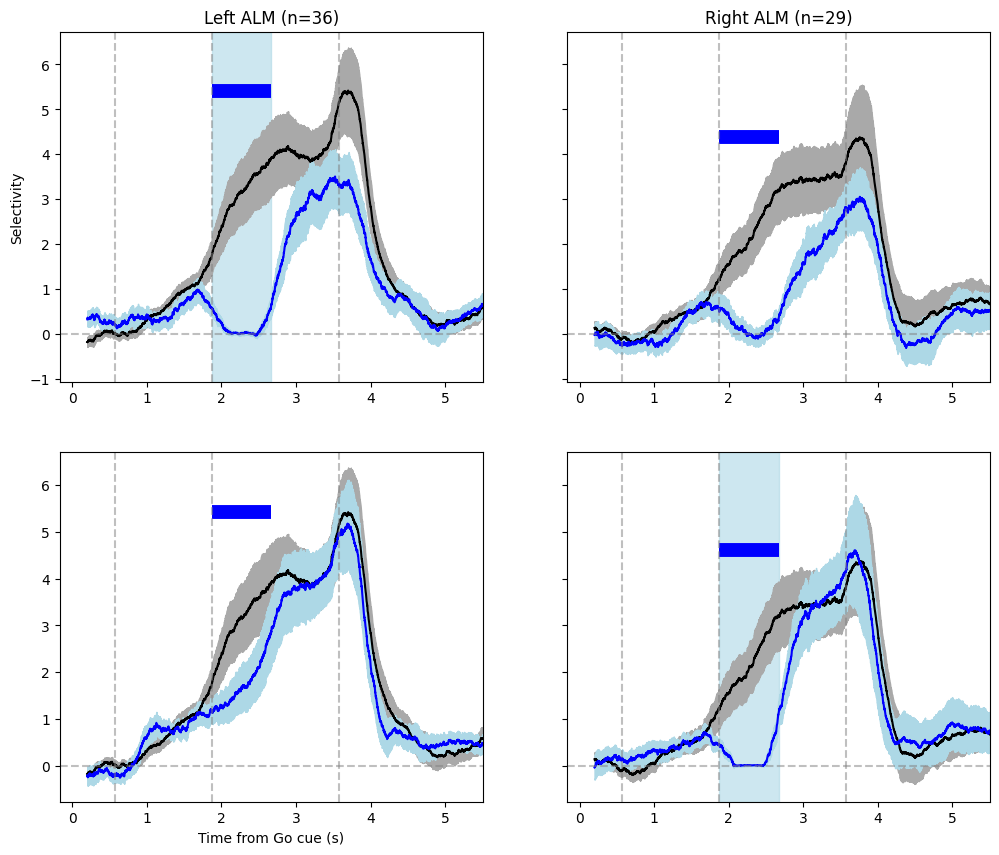

In [39]:
path = r'M:\\data\\CW89\\python\\2026_05_15'
s1=Session(path, passive=False, filter_low_perf=True, filter_by_stim=True)
s1.delay=0.57+1.3
s1.response=0.57+1.3+1.7
epoch = (s1.delay, s1.response)
left_info, right_info = s1.selectivity_optogenetics(epoch = epoch,
                                                    p=0.01, 
                                                    binsize=400, 
                                                    timestep=150,
                                                    # binsize=200, 
                                                    # timestep=100,
                                                    bootstrap=True)

ax = plot_selectivity_recovery(s1, left_info, right_info, save=r'P:\paperfigures\fig5\selectivity_recovery_Ldom.pdf')
# plt.savefig(r'P:\paperfigures\fig5\selectivity_recovery_Ldom.pdf')

### Scatter of robustness colored by successful vs not

Remove 38 trials from session for bad behavior
47 trials removed for stability reasons
only ppyr neurons: 359 --> 305
Remove 0 trials from session for bad behavior
7 trials removed for stability reasons
only ppyr neurons: 458 --> 375
Remove 0 trials from session for bad behavior
13 trials removed for stability reasons
only ppyr neurons: 193 --> 146
Remove 0 trials from session for bad behavior
18 trials removed for stability reasons
only ppyr neurons: 339 --> 286
Remove 0 trials from session for bad behavior
4 trials removed for stability reasons
only ppyr neurons: 222 --> 184
Loading good trial inds from file
20 trials removed for stability reasons
only ppyr neurons: 271 --> 201
Loading good trial inds from file
11 trials removed for stability reasons
only ppyr neurons: 296 --> 198
Loading good trial inds from file
16 trials removed for stability reasons
only ppyr neurons: 225 --> 169
Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 280 --> 2

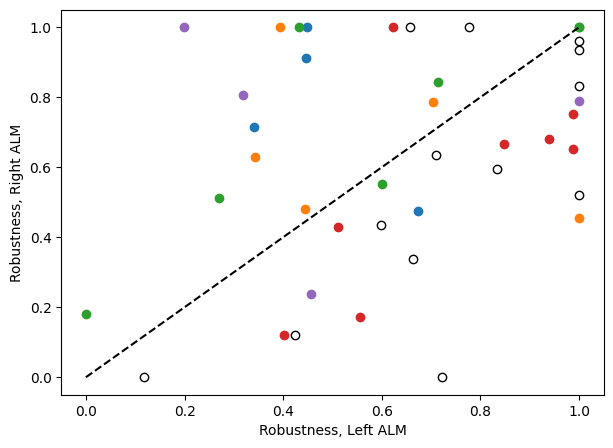

In [57]:
f=plt.figure(figsize=(7,5))
all_corr_all_opto_prop_stim_left, all_corr_all_opto_prop_stim_right = [],[]
# for path in cat(all_learning_paths_stimcorrected):
filt_cor_paths = []
for paths in corr_paths:
    addpath = []
    corr_all_opto_prop_stim_left, corr_all_opto_prop_stim_right = [],[]

    for path in paths:
        s1 = Session(path, passive=False, filter_low_perf=True, filter_by_stim=True)
        # s1.filter_low_performance(threshold=0.550, consec_len=20)
        if 'CW59' in path:
            s1.delay = 0.57+1.3
            s1.response = 0.57+1.3+3
            epoch = (s1.delay+1, s1.response)

        else:
            s1.delay = 0.57+1.3
            s1.response = 0.57+1.3+1.7
            epoch = (s1.delay+0.1, s1.response)
        # epoch = (s1.sample, s1.delay)
        left_info, right_info = s1.selectivity_optogenetics(epoch=epoch,
                                                            p=0.01, 
                                                            # p=0.05/len(s1.good_neurons), 
                                                            binsize=400, 
                                                            timestep=100,
                                                            return_traces=True,
                                                            bootstrap=True)
        # sel, selo_stimleft, selo_stimright, err, erro_stimleft, erro_stimright, time = left_info
        # sel_R, selo_stimleft_R, selo_stimright_R, err_R, erro_stimleft_R, erro_stimright_R, time = right_info
        
        control_sel, opto_sel_stim_left, opto_sel_stim_right, time = left_info
        control_sel_R, opto_sel_stim_left_R, opto_sel_stim_right_R, _ = right_info
    
        period = np.where((time > s1.delay) & (time < s1.delay + 0.8))[0] # Coupling
        
        period = np.where((time > s1.delay + 1) & (time < s1.response))[0] # Robustness
        period = np.where((time > s1.delay + 1) & (time < s1.response))[0]  if 'CW59' in path else np.where((time > s1.delay + 1.3) & (time < s1.response))[0] # Robustness

        early_delay = np.where((time > s1.delay) & (time < s1.delay + 1))[0]
        late_delay = np.where((time > s1.delay + 1) & (time < s1.response))[0]
        
        # Filtering criteria
        n_thres = 3
        if len(control_sel_R) > n_thres and len(control_sel) > n_thres:
            # if np.mean(np.mean(control_sel_R, axis=0)[early_delay]) >= 0.5 and np.mean(np.mean(control_sel, axis=0)[early_delay]) >= 0.5:
            #     if np.mean(np.mean(control_sel_R, axis=0)[late_delay]) >= 1 and np.mean(np.mean(control_sel, axis=0)[late_delay]) >= 1:

            selo_stimright = np.mean(opto_sel_stim_right, axis=0)
            sel = np.mean(control_sel, axis=0)
            selo_stimleft_R = np.mean(opto_sel_stim_left_R, axis=0)
            sel_R = np.mean(control_sel_R, axis=0)
            
            corr_all_opto_prop_stim_left += [np.mean(selo_stimright[period]) / np.mean(sel[period])]
            corr_all_opto_prop_stim_right += [np.mean(selo_stimleft_R[period]) / np.mean(sel_R[period])]

            addpath += [path]


            # selo_stimright = np.mean(opto_sel_stim_right, axis=0)
            # selo_stimright_R = np.mean(opto_sel_stim_right_R, axis=0)
            # sel = np.mean(control_sel, axis=0)
            # selo_stimleft_R = np.mean(opto_sel_stim_left_R, axis=0)
            # selo_stimleft = np.mean(opto_sel_stim_left, axis=0)
            # sel_R = np.mean(control_sel_R, axis=0)
            
            # Use both hemispheres for robustness calculations

            # all_opto_prop_stim_right +=[np.mean([np.mean(selo_stimleft_R[period]) / np.mean(sel_R[period]),
            #                                     np.mean(selo_stimleft[period]) / np.mean(sel[period])])]

            # all_opto_prop_stim_left += [np.mean([np.mean(selo_stimright_R[period]) / np.mean(sel_R[period]), 
            #                                         np.mean(selo_stimright[period]) / np.mean(sel[period])])]
    # Filtering steps 
    
    corr_all_opto_prop_stim_left, corr_all_opto_prop_stim_right = np.array(corr_all_opto_prop_stim_left), np.array(corr_all_opto_prop_stim_right)
    corr_all_opto_prop_stim_left[corr_all_opto_prop_stim_left > 1] = 1
    corr_all_opto_prop_stim_right[corr_all_opto_prop_stim_right > 1] = 1
    corr_all_opto_prop_stim_left[corr_all_opto_prop_stim_left < 0] = 0
    corr_all_opto_prop_stim_right[corr_all_opto_prop_stim_right < 0] = 0
    # Plot as a scatter like in Chen et al 
    # modularity of left vs right alm
    
    all_corr_all_opto_prop_stim_left += [corr_all_opto_prop_stim_left]
    all_corr_all_opto_prop_stim_right += [corr_all_opto_prop_stim_right]
        
    
    plt.scatter(corr_all_opto_prop_stim_left, corr_all_opto_prop_stim_right, label = path)
    filt_cor_paths += [addpath]
plt.plot([0,1], [0,1], ls='--', color='black')
plt.scatter(all_opto_prop_stim_left, all_opto_prop_stim_right, facecolors='white', edgecolors='black')
plt.ylabel('Robustness, Right ALM')
plt.xlabel('Robustness, Left ALM')
# plt.legend()
plt.show()

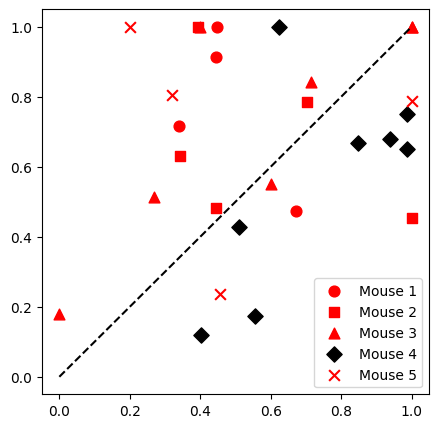

In [51]:
marker_styles = ['o', 's', '^', 'D', 'x']
f = plt.figure(figsize=(5, 5))
for i in range(len(all_corr_all_opto_prop_stim_left)):
    if np.mean(all_corr_all_opto_prop_stim_left[i]) > np.mean(all_corr_all_opto_prop_stim_right[i]):
        plt.scatter(all_corr_all_opto_prop_stim_left[i], all_corr_all_opto_prop_stim_right[i],color='black',marker=marker_styles[i], s=60, label = 'Mouse {}'.format(i+1))
    else:
        plt.scatter(all_corr_all_opto_prop_stim_left[i], all_corr_all_opto_prop_stim_right[i],color='red',marker=marker_styles[i],  s=60, label = 'Mouse {}'.format(i+1))

plt.plot([0,1], [0,1], ls='--', color='black')
plt.legend()
plt.savefig(r'P:\paperfigures\fig5\robustness_scatter_within_corr.pdf')
plt.show()

In [52]:
success_indices = [i for i in range(len(all_corr_all_opto_prop_stim_left)) if np.mean(all_corr_all_opto_prop_stim_left[i]) < np.mean(all_corr_all_opto_prop_stim_right[i])]

### Proportion of sample selective neurons

In [74]:
p=0.05
allsel_L_trained = []
allsel_R_trained = []
for paths in filt_cor_paths:
    selL = []
    for path in paths:
        s1 = Session(path,side='L', passive=False, filter_low_perf=False, filter_by_stim=True)
        contra, ipsi = s1.plot_number_of_sig_neurons(return_nums=True, p=p, trialtype=True)
        selL += [(contra + ipsi) / len(s1.good_neurons)]
    allsel_L_trained += [selL]

for paths in filt_cor_paths:
    selR = []
    for path in paths:
        s1 = Session(path,side='R', passive=False, filter_low_perf=False, filter_by_stim=True)
        contra, ipsi = s1.plot_number_of_sig_neurons(return_nums=True, p=p, trialtype=True)
        selR += [(contra + ipsi) / len(s1.good_neurons)]
    allsel_R_trained += [selR]
    

47 trials removed for stability reasons
only ppyr neurons: 252 --> 218
3 trials removed for stability reasons
only ppyr neurons: 210 --> 170
15 trials removed for stability reasons
only ppyr neurons: 164 --> 135
4 trials removed for stability reasons
only ppyr neurons: 125 --> 101
Loading good trial inds from file
20 trials removed for stability reasons
only ppyr neurons: 122 --> 91
Loading good trial inds from file
8 trials removed for stability reasons
only ppyr neurons: 140 --> 90
Loading good trial inds from file
9 trials removed for stability reasons
only ppyr neurons: 111 --> 84
Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 181 --> 133
13 trials removed for stability reasons
only ppyr neurons: 171 --> 142
Loading good trial inds from file
11 trials removed for stability reasons
only ppyr neurons: 202 --> 169
5 trials removed for stability reasons
only ppyr neurons: 300 --> 233
Loading good trial inds from file
15 trials removed for st

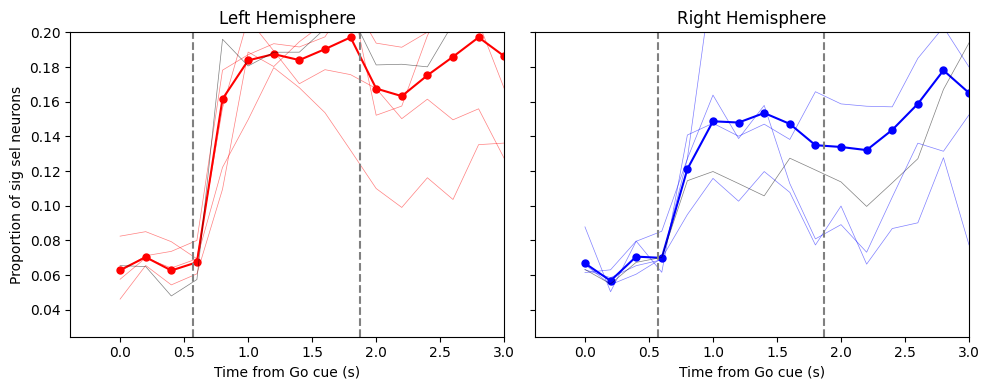

In [75]:
x = np.arange(0, 8.5, 200/1000)

fig, axs = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

# LEFT
axs[0].plot(x[:-3], np.mean(cat(allsel_L_trained), axis=0)[:-3], color='r', marker='o', markersize=5)
for i in range(len(allsel_L_trained)):
    if i in success_indices:
        axs[0].plot(x[:-3], np.mean(allsel_L_trained[i], axis=0)[:-3], color='r', alpha=0.5, linewidth=0.5)
    else:
        axs[0].plot(x[:-3], np.mean(allsel_L_trained[i], axis=0)[:-3], color='black', alpha=0.5, linewidth=0.5)

axs[0].axvline(0.57, ls='--', color='grey')
axs[0].axvline(1.87, ls='--', color='grey')
axs[0].axvline(1.87+1.7, ls='--', color='grey')
axs[0].set_ylim(top=0.2)
axs[0].set_xlim(right =3)
# axs[0].set_ylim(bottom=-350)  # Uncomment if bottom limit needed
axs[0].set_ylabel('Proportion of sig sel neurons')
axs[0].set_xlabel('Time from Go cue (s)')
axs[0].set_title('Left Hemisphere')

# RIGHT
axs[1].plot(x[:-3], np.mean(cat(allsel_R_trained), axis=0)[:-3], color='b', marker='o', markersize=5)
for i in range(len(allsel_R_trained)):
    if i in success_indices:
        axs[1].plot(x[:-3], np.mean(allsel_R_trained[i], axis=0)[:-3], color='b', alpha=0.5, linewidth=0.5)
    else:
        axs[1].plot(x[:-3], np.mean(allsel_R_trained[i], axis=0)[:-3], color='black', alpha=0.5, linewidth=0.5)
axs[1].axvline(0.57, ls='--', color='grey')
axs[1].axvline(1.87, ls='--', color='grey')
axs[1].axvline(1.87+1.7, ls='--', color='grey')
axs[1].set_ylim(top=0.2)
axs[1].set_xlim(right =3)
# axs[1].set_ylim(bottom=-350)  # Uncomment if bottom limit needed
axs[1].set_xlabel('Time from Go cue (s)')
axs[1].set_title('Right Hemisphere')

plt.tight_layout()


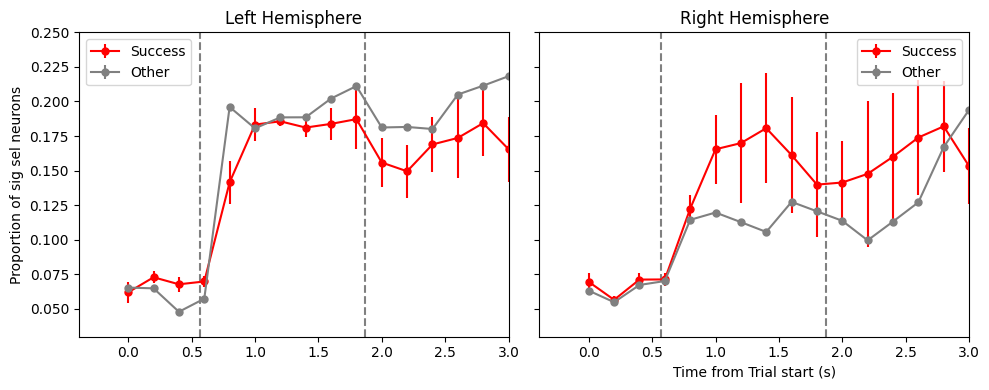

In [79]:
from scipy.stats import sem

x = np.arange(0, 8.5, 200/1000)

fig, axs = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

# get indices for successes and failures
success_mask = np.array([i in success_indices for i in range(len(allsel_L_trained))])
failure_mask = ~success_mask

# --- LEFT ---
allsel_L = np.array([np.mean(sel, axis=0) for sel in allsel_L_trained])  # shape: [n_sessions, n_timebins]

left_success = allsel_L[success_mask]
left_failure = allsel_L[failure_mask]

mean_left_success = np.mean(left_success, axis=0)
sem_left_success = sem(left_success, axis=0)
mean_left_failure = np.mean(left_failure, axis=0)
sem_left_failure = sem(left_failure, axis=0)

axs[0].errorbar(x[:-3], mean_left_success[:-3], yerr=sem_left_success[:-3], color='r', marker='o', markersize=5, label='Success')
axs[0].errorbar(x[:-3], mean_left_failure[:-3], yerr=sem_left_failure[:-3], color='grey', marker='o', markersize=5, label='Other')

axs[0].axvline(0.57, ls='--', color='grey')
axs[0].axvline(1.87, ls='--', color='grey')
axs[0].axvline(1.87+1.7, ls='--', color='grey')
# axs[0].set_ylim(top=0.2)
axs[0].set_xlim(right=3)
# axs[0].set_ylim(bottom=-350)  # Uncomment if bottom limit needed
axs[0].set_ylabel('Proportion of sig sel neurons')
axs[1].set_xlabel('Time from Trial start (s)')
axs[0].set_title('Left Hemisphere')
axs[0].legend()

# --- RIGHT ---
success_mask_right = np.array([i in success_indices for i in range(len(allsel_R_trained))])
failure_mask_right = ~success_mask_right

allsel_R = np.array([np.mean(sel, axis=0) for sel in allsel_R_trained])  # shape: [n_sessions, n_timebins]

right_success = allsel_R[success_mask_right]
right_failure = allsel_R[failure_mask_right]

mean_right_success = np.mean(right_success, axis=0)
sem_right_success = sem(right_success, axis=0)
mean_right_failure = np.mean(right_failure, axis=0)
sem_right_failure = sem(right_failure, axis=0)

axs[1].errorbar(x[:-3], mean_right_success[:-3], yerr=sem_right_success[:-3], color='r', marker='o', markersize=5, label='Success')
axs[1].errorbar(x[:-3], mean_right_failure[:-3], yerr=sem_right_failure[:-3], color='grey', marker='o', markersize=5, label='Other')

axs[1].axvline(0.57, ls='--', color='grey')
axs[1].axvline(1.87, ls='--', color='grey')
axs[1].axvline(1.87+1.7, ls='--', color='grey')
axs[1].set_ylim(top=0.25)
axs[1].set_xlim(right=3)
# axs[1].set_ylim(bottom=-350)  # Uncomment if bottom limit needed
axs[1].set_xlabel('Time from Trial start (s)')
axs[1].set_title('Right Hemisphere')
axs[1].legend()
plt.tight_layout()

plt.savefig(r'P:\paperfigures\fig5\prop_sig_neurons_LvR_p05.pdf')



In [50]:
success_indices

[0, 1, 2, 4]

### Sample selectivity scatter

In [ ]:
if False:
    left_sel, right_sel = [],[]
    for path in cat(allpaths):
        s1 = Session(path, passive=False, side='L', anterior_shank=False)
        
        p=0.05/len(s1.good_neurons)
        p=0.05
        all_neurons = s1.get_epoch_selective(epoch=(s1.sample, s1.delay), p=p)
        epochs = [(s1.sample, s1.delay) for _ in range(len(all_neurons))]
        # epochs = [(s1.delay, s1.response) for _ in range(len(all_neurons))]
        sel, time = s1.plot_selectivity(all_neurons, binsize=200, timestep=50, return_pref_np=False, epoch=epochs)
        sample_idx = np.where((time < s1.delay) & (time > s1.sample))
        sample_idx = np.where((time < s1.response) & (time > s1.delay))
        lsel = np.mean(np.array(sel)[:, sample_idx])
        left_sel += [lsel]
        
        s1 = Session(path, passive=False, side='R', anterior_shank=False)
        all_neurons = s1.get_epoch_selective(epoch=(s1.sample, s1.delay), p=p)
        epochs = [(s1.sample, s1.delay) for _ in range(len(all_neurons))]
        # epochs = [(s1.delay, s1.response) for _ in range(len(all_neurons))]

        sel, time = s1.plot_selectivity(all_neurons, binsize=200, timestep=50, return_pref_np=False, epoch=epochs)
        sample_idx = np.where((time < s1.delay) & (time > s1.sample))
        sample_idx = np.where((time < s1.response) & (time > s1.delay))

        rsel = np.mean(np.array(sel)[:, sample_idx])
        right_sel += [rsel]
    
all_corr_left_sel, all_corr_right_sel = [],[]

for paths in filt_cor_paths:
    corr_left_sel, corr_right_sel = [],[]
    for path in paths:
        s1 = Session(path, passive=False, side='L', anterior_shank=False)
        
        p=0.01  # was 0.055
        all_neurons = s1.get_epoch_selective(epoch=(s1.sample, s1.delay), p=p)
        epochs = [(s1.sample, s1.delay) for _ in range(len(all_neurons))]
        sel, time = s1.plot_selectivity(all_neurons, binsize=200, timestep=50, return_pref_np=False, epoch=epochs)
        sample_idx = np.where((time < s1.delay) & (time > s1.sample))
        sample_idx = np.where((time < s1.response) & (time > s1.delay))

        lsel = np.mean(np.array(sel)[:, sample_idx])
        corr_left_sel += [lsel]
        
        s1 = Session(path, passive=False, side='R', anterior_shank=False)
        all_neurons = s1.get_epoch_selective(epoch=(s1.sample, s1.delay), p=p)
        epochs = [(s1.sample, s1.delay) for _ in range(len(all_neurons))]
        sel, time = s1.plot_selectivity(all_neurons, binsize=200, timestep=50, return_pref_np=False, epoch=epochs)
        sample_idx = np.where((time < s1.delay) & (time > s1.sample))
        sample_idx = np.where((time < s1.response) & (time > s1.delay))

        rsel = np.mean(np.array(sel)[:, sample_idx])
        corr_right_sel += [rsel]
    

    all_corr_left_sel += [corr_left_sel]
    all_corr_right_sel += [corr_right_sel]



Remove 38 trials from session for bad behavior
47 trials removed for stability reasons
only ppyr neurons: 252 --> 218
Remove 38 trials from session for bad behavior
37 trials removed for stability reasons
only ppyr neurons: 107 --> 87
Remove 0 trials from session for bad behavior
3 trials removed for stability reasons
only ppyr neurons: 210 --> 170
Remove 0 trials from session for bad behavior
7 trials removed for stability reasons
only ppyr neurons: 248 --> 205
Remove 0 trials from session for bad behavior
15 trials removed for stability reasons
only ppyr neurons: 164 --> 135
Remove 0 trials from session for bad behavior
9 trials removed for stability reasons
only ppyr neurons: 175 --> 152
Remove 0 trials from session for bad behavior
4 trials removed for stability reasons
only ppyr neurons: 125 --> 101
Remove 0 trials from session for bad behavior
1 trials removed for stability reasons
only ppyr neurons: 97 --> 83
Loading good trial inds from file
20 trials removed for stability reas

AttributeError: 'Session' object has no attribute 'time'

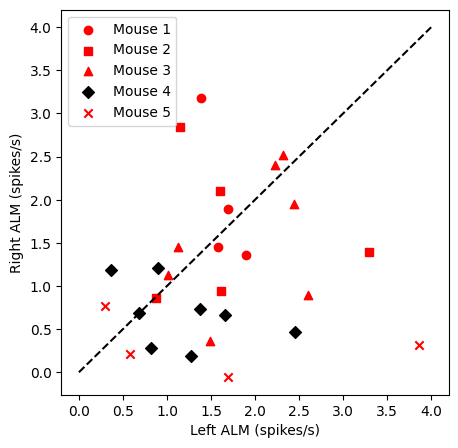

In [ ]:
marker_styles = ['o', 's', '^', 'D', 'x']
f = plt.figure(figsize=(5, 5))

# plot with just corrupted for now
# plt.scatter(left_sel, right_sel, color = 'grey')
for i in range(len(all_corr_left_sel)):

    if i in success_indices:
        plt.scatter(all_corr_left_sel[i], all_corr_right_sel[i], label='Mouse {}'.format(i+1),color='red', marker=marker_styles[i])
    else:
        plt.scatter(all_corr_left_sel[i], all_corr_right_sel[i], label='Mouse {}'.format(i+1),color='black', marker=marker_styles[i])
# plt.scatter(uncorr_left_sel, uncorr_right_sel, color = 'green', label='non-reversed')
plt.plot([0,4],[0,4],ls='--',color='black')
plt.xlabel('Left ALM (spikes/s)')
plt.ylabel('Right ALM (spikes/s)')
plt.legend()
plt.savefig(r'P:\paperfigures\fig5\sample_selectivityLvR.pdf')

## Learning speed